# Model 3 — Gradient boosting (XGBoost)
**Question:** Which behavioral characteristics best predict 1-year % weight change among U.S. adults who tried to lose weight, beyond demographics and starting BMI? (NHANES Aug 2021–Aug 2023, n = 2,794)

**Design:** XGBoost is fitted twice:
- **Covariates only** — 15 demographic predictors + BMI 1 year ago
- **Covariates + behaviors** — the 15 above plus 12 behavioral predictors

Gradient boosting builds many small decision trees in sequence, each correcting the errors of the ones before. It can capture **non-linear** relationships and **interactions** (e.g., activity mattering more at higher starting BMI) without these being specified in advance.

Comparing the two fits (ΔR², ΔRMSE on the held-out test set, with bootstrap CIs) answers "beyond demographics and starting BMI"; permutation importance and SHAP values answer "which behaviors".

Outcome: `pct_wt_change` = (current − 1 yr ago) ÷ 1 yr ago × 100, restricted to ±50%. Negative = weight lost.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
DATA_PATH = "nhanes_model_ready.csv"   # keep the CSV next to this notebook
OUTCOME = "pct_wt_change"

# NHANES design variables: kept for reference, never used as predictors
ID_COL, WT_COL = "Respondent sequence number", "Full sample 2-year MEC exam weight"
# Set to True to fit and score with the MEC exam weights (population-weighted fit).
# Default False: a standard (unweighted) prediction model, as most ML comparisons do.
USE_SURVEY_WEIGHTS = False

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
import xgboost as xgb
import shap
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from scipy.stats import uniform, randint, loguniform

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load data and define predictor sets
The CSV is already cleaned, but a few predictors still have missing values (notably PHQ-9, drinks/week and income-to-poverty ratio, each ~12%). XGBoost handles missing values natively (it learns which branch missing values go down at each split), so no imputation is needed.

In [ ]:
df = pd.read_csv(DATA_PATH)

COVARIATES = [
    "age", "female",
    "race_eth_Mexican American", "race_eth_Other Hispanic", "race_eth_NH Black",
    "race_eth_NH Asian", "race_eth_Other/Multiracial",
    "education", "income_poverty_ratio",
    "marital_Widowed/divorced/separated", "marital_Never married",
    "household_size", "us_born", "veteran", "bmi_1yr_ago",
]
BEHAVIORS = [
    "mod_min_wk", "vig_min_wk", "sedentary_hr_day", "phq9_score",
    "drinks_per_week", "sleep_hr_avg",
    "smoking_status_Former", "smoking_status_Current",
    "main_meal_planner", "shares_meal_planning", "main_food_shopper", "shares_food_shopping",
]
FULL = COVARIATES + BEHAVIORS
assert len(COVARIATES) == 15 and len(BEHAVIORS) == 12
assert set(FULL).issubset(df.columns)

print(df.shape)
print(f"Outcome: mean {df[OUTCOME].mean():.2f}%, SD {df[OUTCOME].std():.2f}%, range {df[OUTCOME].min():.1f} to {df[OUTCOME].max():.1f}")
miss = df[FULL].isna().sum()
print("\nPredictors with missing values (handled inside the modeling pipeline):")
print(miss[miss > 0].sort_values(ascending=False).to_frame("n_missing").assign(pct=lambda t: (100 * t.n_missing / len(df)).round(1)))

(2794, 33)
Outcome: mean -1.22%, SD 8.85%, range -40.1 to 50.0

Predictors with missing values (handled inside the modeling pipeline):
                                    n_missing   pct
drinks_per_week                           346  12.4
phq9_score                                333  11.9
income_poverty_ratio                      325  11.6
sleep_hr_avg                               34   1.2
mod_min_wk                                 15   0.5
vig_min_wk                                 15   0.5
bmi_1yr_ago                                11   0.4
sedentary_hr_day                            9   0.3
smoking_status_Former                       2   0.1
smoking_status_Current                      2   0.1
marital_Never married                       1   0.0
marital_Widowed/divorced/separated          1   0.0
shares_meal_planning                        1   0.0
main_food_shopper                           1   0.0


## 2. Train / test split
One held-out test set (20%), stratified on outcome quintiles, with a fixed random seed for reproducibility. All tuning happens with cross-validation on the training set only.

In [ ]:
y = df[OUTCOME]
w = df[WT_COL] if USE_SURVEY_WEIGHTS else pd.Series(1.0, index=df.index)

# stratify on outcome quintiles so the heavy tails land in both sets
strata = pd.qcut(y, 5, labels=False, duplicates="drop")
idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)

y_train, y_test = y.loc[idx_train], y.loc[idx_test]
w_train, w_test = w.loc[idx_train], w.loc[idx_test]
print(f"train n={len(idx_train)}, test n={len(idx_test)}")
print(f"train mean={y_train.mean():.2f}, test mean={y_test.mean():.2f}")

train n=2235, test n=559
train mean=-1.30, test mean=-0.91


In [ ]:
def metrics(y_true, y_pred, weights=None):
    return {
        "R2": r2_score(y_true, y_pred, sample_weight=weights),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred, sample_weight=weights)),
        "MAE": mean_absolute_error(y_true, y_pred, sample_weight=weights),
    }

def bootstrap_delta(y_true, pred_a, pred_b, weights=None, n_boot=2000, seed=RANDOM_STATE):
    """Paired bootstrap on the test set: change in R2 and RMSE going from model A to model B."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    wts = np.ones_like(y_true) if weights is None else np.asarray(weights)
    d_r2, d_rmse = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        ma, mb = metrics(y_true[i], pred_a[i], wts[i]), metrics(y_true[i], pred_b[i], wts[i])
        d_r2.append(mb["R2"] - ma["R2"]); d_rmse.append(mb["RMSE"] - ma["RMSE"])
    out = {}
    for name, arr in [("dR2", np.array(d_r2)), ("dRMSE", np.array(d_rmse))]:
        out[name] = (arr.mean(), *np.percentile(arr, [2.5, 97.5]))
    return out

TEST_W = w_test.values if USE_SURVEY_WEIGHTS else None
FIT_W = w_train.values if USE_SURVEY_WEIGHTS else None

In [ ]:
# Reference point: predict the training mean for everyone
baseline_pred = np.full(len(y_test), np.average(y_train, weights=w_train))
pd.DataFrame([metrics(y_test, baseline_pred, TEST_W)], index=["Mean-only baseline"]).round(3)

,R2,RMSE,MAE
Mean-only baseline,-0.002,9.089,6.28


## 3. Hyperparameter tuning
Randomized search (60 candidates × 5-fold CV on the training set), separately for each predictor set. The search favors shallow trees, a small learning rate and strong regularization; with a noisy outcome and n ≈ 2,200 training rows, boosting overfits easily. Tuning takes a few minutes.

In [ ]:
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
FEATURE_SETS = {"Covariates": COVARIATES, "Covariates + behaviors": FULL}

param_dist = {
    "n_estimators": randint(100, 800),
    "learning_rate": loguniform(0.005, 0.1),
    "max_depth": randint(2, 6),
    "min_child_weight": randint(5, 60),
    "subsample": uniform(0.5, 0.5),
    "colsample_bytree": uniform(0.4, 0.6),
    "reg_lambda": loguniform(0.1, 50),
    "reg_alpha": loguniform(1e-3, 10),
    "gamma": uniform(0, 2),
}
base = xgb.XGBRegressor(objective="reg:squarederror", tree_method="hist",
                        random_state=RANDOM_STATE, n_jobs=-1)

searches = {}
for s_name, cols in FEATURE_SETS.items():
    s = RandomizedSearchCV(base, param_dist, n_iter=60, cv=CV, scoring="neg_root_mean_squared_error",
                           random_state=RANDOM_STATE, n_jobs=1, refit=True)
    s.fit(df.loc[idx_train, cols], y_train, sample_weight=FIT_W)
    searches[s_name] = s
    print(f"{s_name}: best CV RMSE = {-s.best_score_:.3f}")
    print("   ", {k: round(v, 4) if isinstance(v, float) else v for k, v in s.best_params_.items()})

Covariates: best CV RMSE = 8.178
    {'colsample_bytree': np.float64(0.9843), 'gamma': np.float64(0.4655), 'learning_rate': np.float64(0.0066), 'max_depth': 3, 'min_child_weight': 55, 'n_estimators': 666, 'reg_alpha': np.float64(8.5689), 'reg_lambda': np.float64(1.8188), 'subsample': np.float64(0.93)}


Covariates + behaviors: best CV RMSE = 8.124
    {'colsample_bytree': np.float64(0.8253), 'gamma': np.float64(1.1056), 'learning_rate': np.float64(0.0122), 'max_depth': 3, 'min_child_weight': 39, 'n_estimators': 507, 'reg_alpha': np.float64(4.4974), 'reg_lambda': np.float64(2.3994), 'subsample': np.float64(0.7508)}


## 4. Test-set performance

In [ ]:
fitted, preds, rows = {}, {}, []
for s_name, cols in FEATURE_SETS.items():
    m = searches[s_name].best_estimator_
    p = m.predict(df.loc[idx_test, cols])
    fitted[s_name], preds[s_name] = m, p
    rows.append({"Model": "XGBoost", "Predictors": s_name, "CV RMSE": -searches[s_name].best_score_,
                 **metrics(y_test, p, TEST_W)})
results = pd.DataFrame(rows).set_index(["Model", "Predictors"])
results.round(4)

CV RMSE      R2    RMSE     MAE
Model   Predictors                                             
XGBoost Covariates               8.1777  0.0646  8.7825  6.1083
        Covariates + behaviors   8.1239  0.0746  8.7354  6.1117

## 5. Do behaviors add predictive value?
**Test set:** paired bootstrap of ΔR² and ΔRMSE (covariates → covariates + behaviors).
**Repeated CV:** 5-fold × 5 repeats on the training set, with each predictor set's tuned hyperparameters held fixed.

In [ ]:
d = bootstrap_delta(y_test, preds["Covariates"], preds["Covariates + behaviors"], TEST_W)
delta_test = pd.DataFrame([{"Model": "XGBoost",
    "ΔR² (test)": d["dR2"][0], "ΔR² 95% CI": f"[{d['dR2'][1]:.3f}, {d['dR2'][2]:.3f}]",
    "ΔRMSE (test)": d["dRMSE"][0], "ΔRMSE 95% CI": f"[{d['dRMSE'][1]:.3f}, {d['dRMSE'][2]:.3f}]"}]).set_index("Model")
delta_test.round(4)

,ΔR² (test),ΔR² 95% CI,ΔRMSE (test),ΔRMSE 95% CI
Model,,,,
XGBoost,0.0099,"[-0.015, 0.033]",-0.0465,"[-0.155, 0.068]"


In [ ]:
from sklearn.base import clone
rcv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
scores = {}
for s_name, cols in FEATURE_SETS.items():
    scores[s_name] = cross_validate(clone(fitted[s_name]), df.loc[idx_train, cols], y_train, cv=rcv,
                                    scoring=["r2", "neg_root_mean_squared_error"],
                                    params={"sample_weight": FIT_W} if USE_SURVEY_WEIGHTS else None)
diff = scores["Covariates + behaviors"]["test_r2"] - scores["Covariates"]["test_r2"]
cv_results = pd.DataFrame({s: {"CV R2 mean": r["test_r2"].mean(), "CV R2 SD": r["test_r2"].std(),
                               "CV RMSE mean": -r["test_neg_root_mean_squared_error"].mean()}
                           for s, r in scores.items()}).T
print(f"Mean ΔR² across folds: {diff.mean():.4f}  (behaviors better in {(diff > 0).sum()}/{len(diff)} folds)")
cv_results.round(4)

Mean ΔR² across folds: 0.0109  (behaviors better in 22/25 folds)


,CV R2 mean,CV R2 SD,CV RMSE mean
Covariates,0.1269,0.0297,8.1882
Covariates + behaviors,0.1378,0.0303,8.1366


## 6. Which behaviors matter?
Three complementary views on the full model:
1. **Permutation importance** (test set): how much test R² drops when a predictor is shuffled. Model-agnostic, so it does not depend on how the trees were built.
2. **Grouped permutation**: shuffle *all* behaviors together vs. all covariates together, to quantify the behavior block's total contribution.
3. **SHAP values**: direction and shape of each predictor's effect, per person.

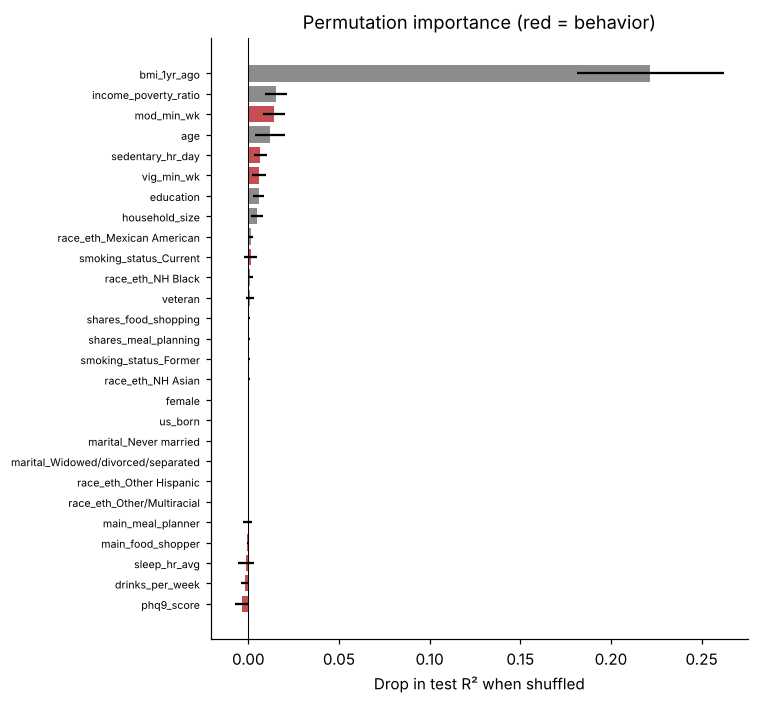

,mean_drop_R2,sd,ci_low,ci_high,group
bmi_1yr_ago,0.2216,0.0405,0.1380,0.2981,Covariate
income_poverty_ratio,0.0152,0.0060,0.0017,0.0268,Covariate
mod_min_wk,0.0142,0.0061,0.0039,0.0250,Behavior
age,0.0120,0.0084,-0.0067,0.0270,Covariate
sedentary_hr_day,0.0066,0.0036,-0.0001,0.0131,Behavior
vig_min_wk,0.0060,0.0039,-0.0018,0.0129,Behavior
education,0.0057,0.0029,0.0005,0.0111,Covariate
household_size,0.0048,0.0034,-0.0010,0.0106,Covariate
race_eth_Mexican American,0.0014,0.0011,-0.0005,0.0035,Covariate
smoking_status_Current,0.0013,0.0034,-0.0046,0.0081,Behavior


In [ ]:
full = fitted["Covariates + behaviors"]
X_test_full = df.loc[idx_test, FULL]
pi = permutation_importance(full, X_test_full, y_test, scoring="r2", n_repeats=50,
                            random_state=RANDOM_STATE, sample_weight=TEST_W)
perm = pd.DataFrame({"mean_drop_R2": pi.importances_mean, "sd": pi.importances_std,
                     "ci_low": np.percentile(pi.importances, 2.5, axis=1),
                     "ci_high": np.percentile(pi.importances, 97.5, axis=1)}, index=FULL)
perm["group"] = ["Behavior" if c in BEHAVIORS else "Covariate" for c in perm.index]
perm = perm.sort_values("mean_drop_R2", ascending=False)

fig, ax = plt.subplots(figsize=(7, 6.5))
pp = perm.iloc[::-1]
ax.barh(pp.index, pp.mean_drop_R2, xerr=pp.sd, color=["#C44E52" if g == "Behavior" else "#8C8C8C" for g in pp.group])
ax.axvline(0, color="k", lw=0.7); ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("Drop in test R² when shuffled"); ax.set_title("Permutation importance (red = behavior)")
plt.tight_layout(); plt.show()
perm.round(4)

In [ ]:
def grouped_permutation(model, X, y, groups, n_repeats=100, weights=None, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base_r2 = r2_score(y, model.predict(X), sample_weight=weights)
    out = {}
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            perm_idx = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[perm_idx]          # shuffle the block jointly, keeping within-block structure
            drops.append(base_r2 - r2_score(y, model.predict(Xp), sample_weight=weights))
        out[g] = {"mean_drop_R2": np.mean(drops), "ci_low": np.percentile(drops, 2.5), "ci_high": np.percentile(drops, 97.5)}
    return pd.DataFrame(out).T

grouped_permutation(full, X_test_full, y_test,
                    {"All behaviors (12)": BEHAVIORS, "All covariates (15)": COVARIATES}, weights=TEST_W).round(4)

,mean_drop_R2,ci_low,ci_high
All behaviors (12),0.0235,-0.0016,0.0466
All covariates (15),0.2457,0.1794,0.3139


### SHAP
Each dot is one test-set participant. Position on the x-axis = how much that predictor pushed their predicted weight change up (gain) or down (loss); color = predictor value.

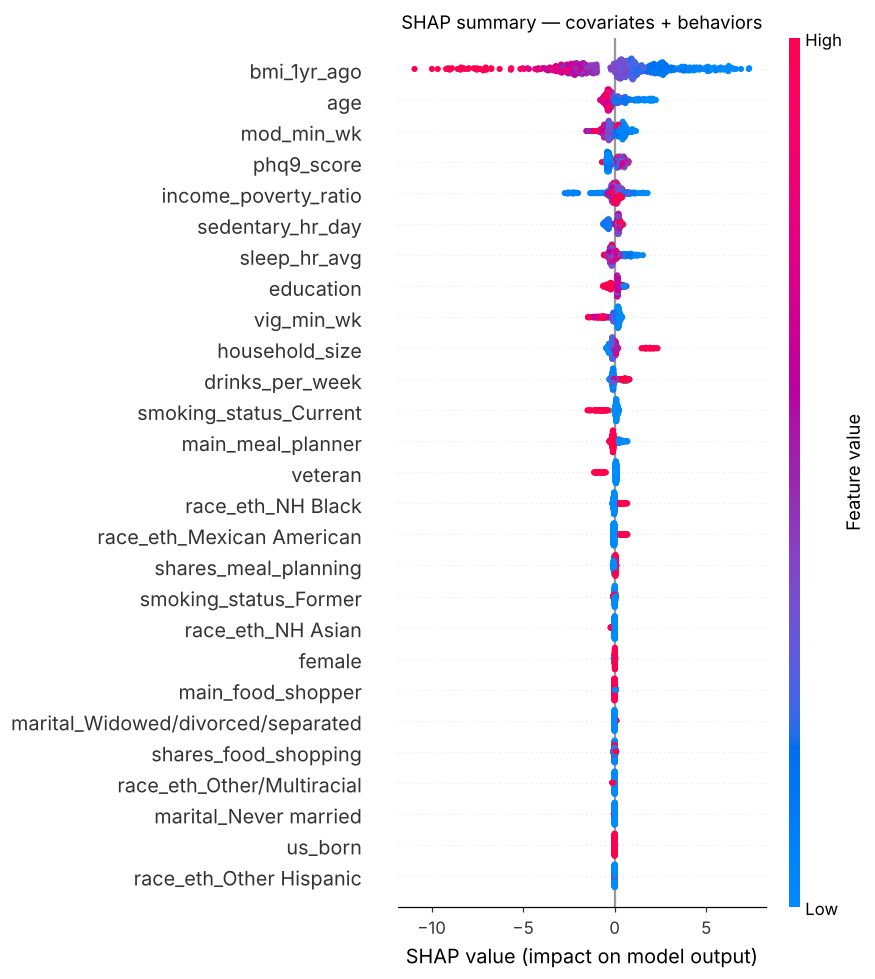

,mean_|SHAP|,group
bmi_1yr_ago,2.5468,Covariate
age,0.4685,Covariate
mod_min_wk,0.4059,Behavior
phq9_score,0.3279,Behavior
income_poverty_ratio,0.3148,Covariate
sedentary_hr_day,0.2807,Behavior
sleep_hr_avg,0.2512,Behavior
education,0.2437,Covariate
vig_min_wk,0.2432,Behavior
household_size,0.2181,Covariate


In [ ]:
explainer = shap.TreeExplainer(full)
shap_values = explainer(X_test_full)

shap.plots.beeswarm(shap_values, max_display=27, show=False)
plt.gcf().set_size_inches(8, 9); plt.title("SHAP summary — covariates + behaviors"); plt.tight_layout(); plt.show()

shap_imp = pd.Series(np.abs(shap_values.values).mean(0), index=FULL, name="mean_|SHAP|").sort_values(ascending=False)
shap_imp.to_frame().assign(group=lambda t: ["Behavior" if c in BEHAVIORS else "Covariate" for c in t.index]).round(4)

### Shape of the top behavioral effects
SHAP dependence plots for the most important behaviors, colored by the predictor each one interacts with most strongly. Curvature, thresholds or plateaus here are patterns a straight-line model could not represent.

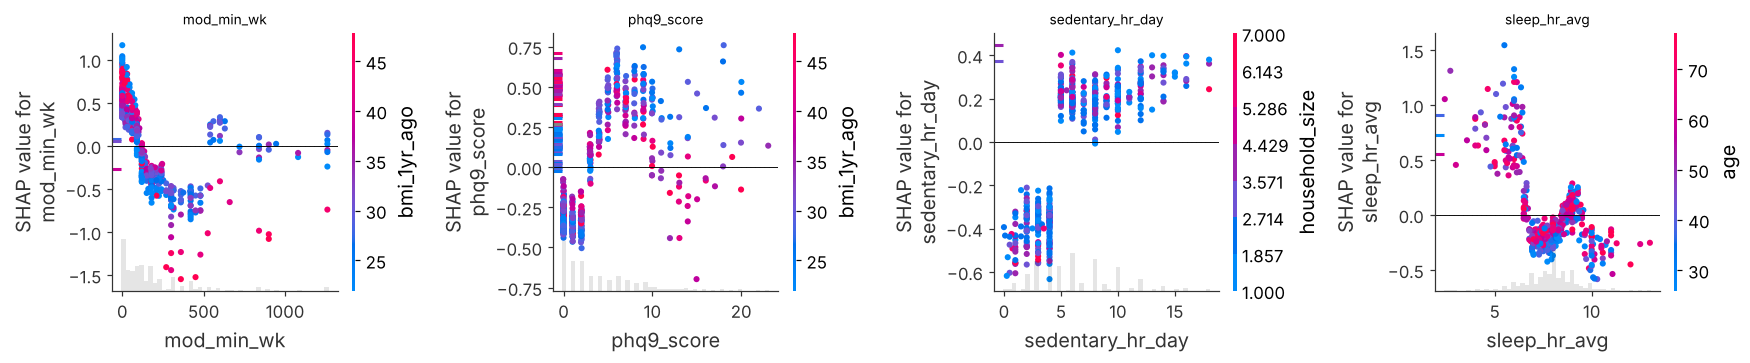

In [ ]:
top_beh = [c for c in shap_imp.index if c in BEHAVIORS][:4]
fig, axes = plt.subplots(1, len(top_beh), figsize=(4 * len(top_beh), 3.4))
for ax, c in zip(np.atleast_1d(axes), top_beh):
    shap.plots.scatter(shap_values[:, c], color=shap_values, ax=ax, show=False)
    ax.axhline(0, color="k", lw=0.6); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
# Strongest pairwise interactions (SHAP interaction values)
inter = explainer.shap_interaction_values(X_test_full)
m = np.abs(inter).mean(0); np.fill_diagonal(m, 0)
pairs = [(FULL[i], FULL[j], m[i, j]) for i in range(len(FULL)) for j in range(i + 1, len(FULL))]
inter_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "mean_|interaction|"]).sort_values("mean_|interaction|", ascending=False)
inter_df["involves_behavior"] = inter_df.feature_1.isin(BEHAVIORS) | inter_df.feature_2.isin(BEHAVIORS)
inter_df.head(10).round(4)

,feature_1,feature_2,mean_|interaction|,involves_behavior
185,income_poverty_ratio,bmi_1yr_ago,0.1840,False
273,bmi_1yr_ago,mod_min_wk,0.1182,True
13,age,bmi_1yr_ago,0.1023,False
276,bmi_1yr_ago,phq9_score,0.0903,True
167,education,bmi_1yr_ago,0.0745,False
278,bmi_1yr_ago,sleep_hr_avg,0.0570,True
280,bmi_1yr_ago,smoking_status_Current,0.0527,True
274,bmi_1yr_ago,vig_min_wk,0.0473,True
191,income_poverty_ratio,sleep_hr_avg,0.0434,True
19,age,sleep_hr_avg,0.0378,True


## 7. Residual check

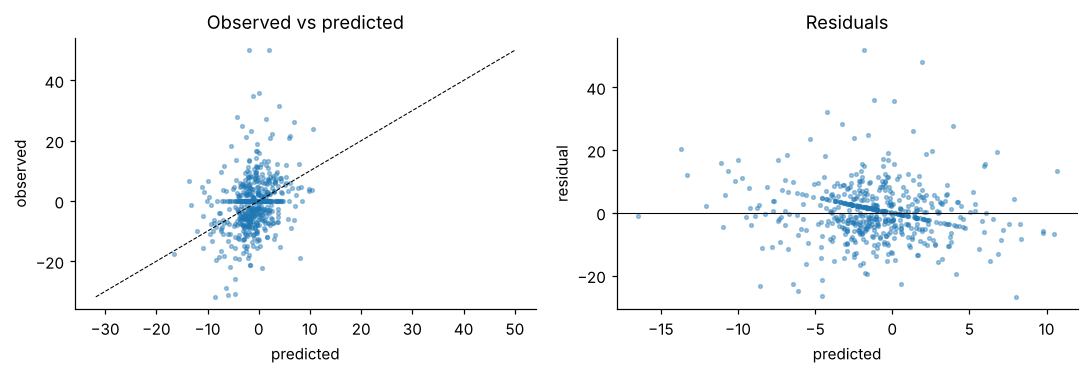

In [ ]:
p = preds["Covariates + behaviors"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(p, y_test, s=6, alpha=0.4); lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "k--", lw=0.7); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed"); ax[0].set_title("Observed vs predicted")
ax[1].scatter(p, y_test - p, s=6, alpha=0.4); ax[1].axhline(0, color="k", lw=0.7)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

## 8. Summary

In [ ]:
summary = results[["R2", "RMSE", "MAE"]].join(delta_test[["ΔR² (test)", "ΔR² 95% CI"]], on="Model")
summary.loc[summary.index.get_level_values("Predictors") == "Covariates", ["ΔR² (test)", "ΔR² 95% CI"]] = np.nan
summary.to_csv("model2_results.csv")
perm.to_csv("model2_permutation_importance.csv")
shap_imp.to_csv("model2_shap_importance.csv")
summary.round(4)

R2    RMSE     MAE  ΔR² (test)       ΔR² 95% CI
Model   Predictors                                                                 
XGBoost Covariates              0.0646  8.7825  6.1083         NaN              NaN
        Covariates + behaviors  0.0746  8.7354  6.1117      0.0099  [-0.015, 0.033]

## Interpretation notes
- Self-reported 1-year weight change is noisy, so low absolute R² is expected; the key question is whether behaviors add a reliable increment over covariates.
- Permutation and SHAP importance describe what the *model* relies on, not causal effects. Correlated predictors (e.g., meal planning and food shopping) share credit, so look at grouped importance too.
- Behaviors were measured at the exam, at the end of the weight-change window, so direction of influence is ambiguous.
- **To use LightGBM instead:** replace `xgb.XGBRegressor(...)` with `lightgbm.LGBMRegressor(random_state=RANDOM_STATE, verbose=-1)` and rename `max_depth`/`min_child_weight` in `param_dist` to `num_leaves`/`min_child_samples`. Everything downstream (including SHAP) works unchanged.